## Generate cell population data for figure 3 for all six conditions

In [1]:
import os
import sys
sys.path.insert(0, "./test_treatments")

In [2]:
import os
import sys
#sys.path.insert(0, "./cellular_cycle") # add path to the model
sys.path.insert(0, "./figures") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
#from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = True # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
sys.path.insert(0, "./cellular_cycle") # add path to the model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

In [4]:
from Cell_Population_Simulation import Cell_Population_Simulation

In [5]:
import thunor


In [6]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt(os.getcwd() + '/model_data/sampled_parameter_names.txt', dtype=str)

In [95]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [8]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + '/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [9]:
initial_concentrations.keys()

Index(['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0',
       'CycD_0', 'CycDp21_0', 'pRb_0', 'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0',
       'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0', 'Cdc20_0',
       'BAX_0', 'BAXmBCL2_0', 'BH3_0', 'BH3BCL2_0', 'BAXm_0', 'BCL2_0'],
      dtype='object')

In [98]:
model.parameters

ComponentSet([
 Parameter('AKT', 0.6),
 Parameter('ERK', 0.2),
 Parameter('FAK', 1.0),
 Parameter('omega', 200.0),
 Parameter('BCL2t', 0.95),
 Parameter('BAXt', 1.0),
 Parameter('s', 0.4),
 Parameter('m', 3.0),
 Parameter('Cdc20_tot', 1.0),
 Parameter('CycE_tot', 1.0),
 Parameter('CycA_tot', 1.0),
 Parameter('CycB_tot', 1.0),
 Parameter('Skp2_0', 0.06),
 Parameter('p21_0', 0.005),
 Parameter('p21p_0', 0.08),
 Parameter('cdh1act_0', 0.03),
 Parameter('cdh1inact_0', 0.97),
 Parameter('Myc_0', 0.695),
 Parameter('CycD_0', 0.235),
 Parameter('CycDp21_0', 0.005),
 Parameter('pRb_0', 0.025),
 Parameter('pRbp_0', 1.21),
 Parameter('E2F_0', 0.62),
 Parameter('pRbE2F_0', 0.095),
 Parameter('CycE_0', 0.815),
 Parameter('CycEp21_0', 0.015),
 Parameter('CycA_0', 0.51),
 Parameter('CycAp21_0', 0.01),
 Parameter('CycB_0', 0.085),
 Parameter('CycBp21_0', 0.01),
 Parameter('Cdc20_0', 0.03),
 Parameter('BAX_0', 0.895),
 Parameter('BAXmBCL2_0', 0.1),
 Parameter('BH3_0', 0.005),
 Parameter('BH3BCL2_0', 0

In [61]:
model.parameters['a_stress'].value = 0 # 0.6515
model.parameters['b_stress_AKT'].value = 0 # 0.112
model.parameters['b_stress_ERK'].value = 0 # 0.0111

In [97]:
model.parameters['a_stress'].value = 0.6515
model.parameters['b_stress_AKT'].value = 0.112
model.parameters['b_stress_ERK'].value = 0.0111

In [11]:
death_mod={'BAX_0': 186 ,'BAXmBCL2_0': 13, 'BH3_0': 0, 'BH3BCL2_0': 7, 'BAXm_0': 0, 'BCL2_0': 70}
for key in initial_concentrations.keys():
    model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value

In [62]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


In [99]:
condition = "55 kPa erlotinib"

In [63]:
# t = np.linspace(0, 10000, 100001)
t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1

In [46]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False);
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False); 

<Axes: xlabel='Time (h)', ylabel='Concentration'>

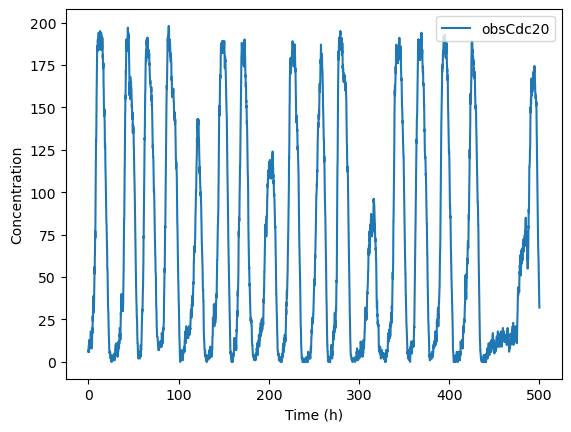

In [47]:
observables=['obsCdc20']
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,5000), legend=True)


In [51]:
from peakfinder import peakfinder
thr = [0.26, 0.18]
return_plot = False

In [52]:
a, max_tmp_cdc = peakfinder(sim_stoch_res.observables['obsCdc20'], thr[0]*model.parameters['omega'].value, thr[0]*model.parameters['omega'].value, 1, includeEndpoints=1)


In [58]:
len(max_tmp_cdc)/20000

0.0342

In [57]:
t[-1]

20000.0

In [ ]:
model.parameters['ERK'].value

In [ ]:
model.parameters['BAX_0'].value

### Run example simulation
Use low stiffness and DMSO treatment as condition. Must use more cells to get decent output.

In [100]:
start_time = datetime.datetime.now()

# Set the species AKT, ERK, FAK with species and value col
# for input in ["AKT", "ERK", "FAK"]:
#     model.parameters[input].value = ECM_conditions[
#         (ECM_conditions["condition"] == condition) & (ECM_conditions["species"] == input)].value

# Set inputs for Cell_Population_Simulation function
init = 5
run_time = 120
observed_cells_time = 120

55 kPa erlotinib


2024-02-27 12:01:13.526 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


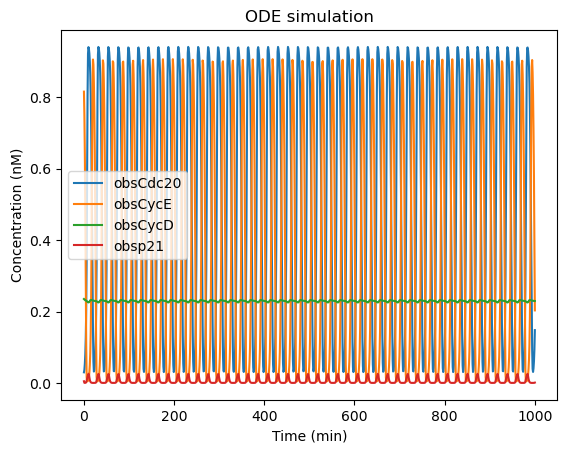

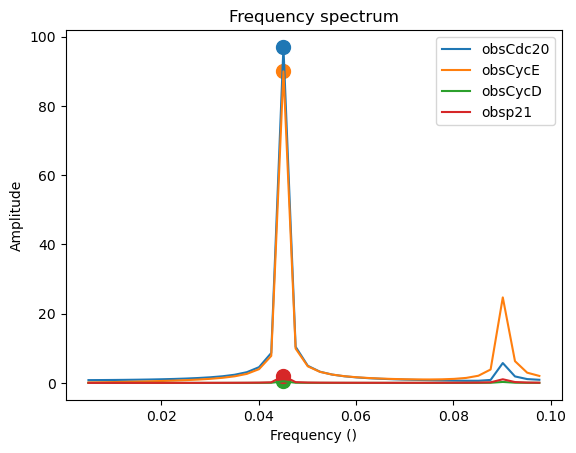

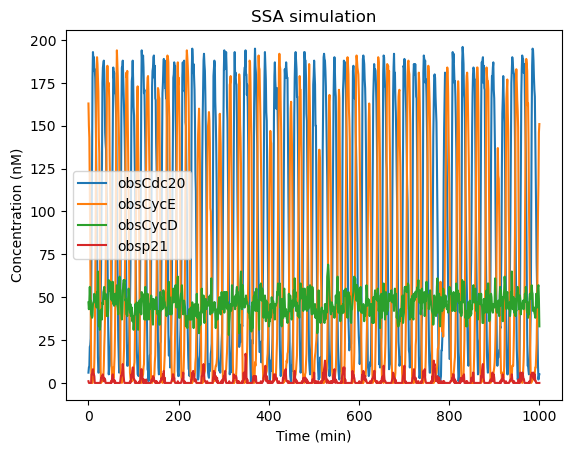

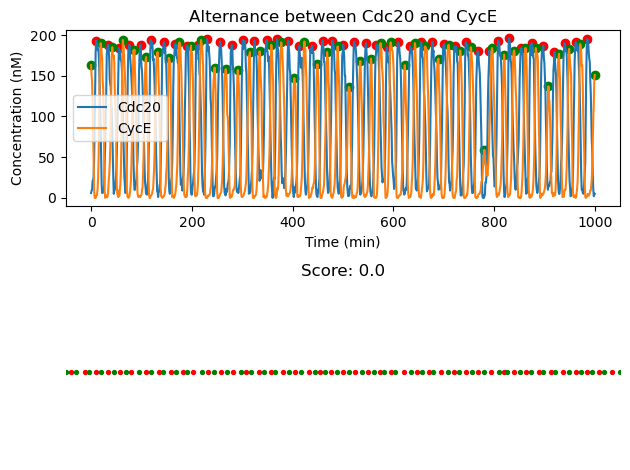

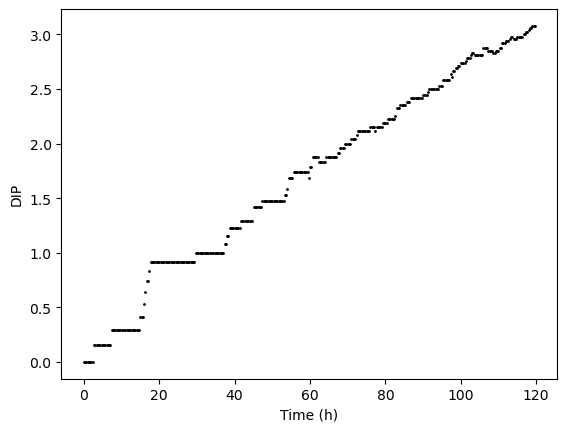

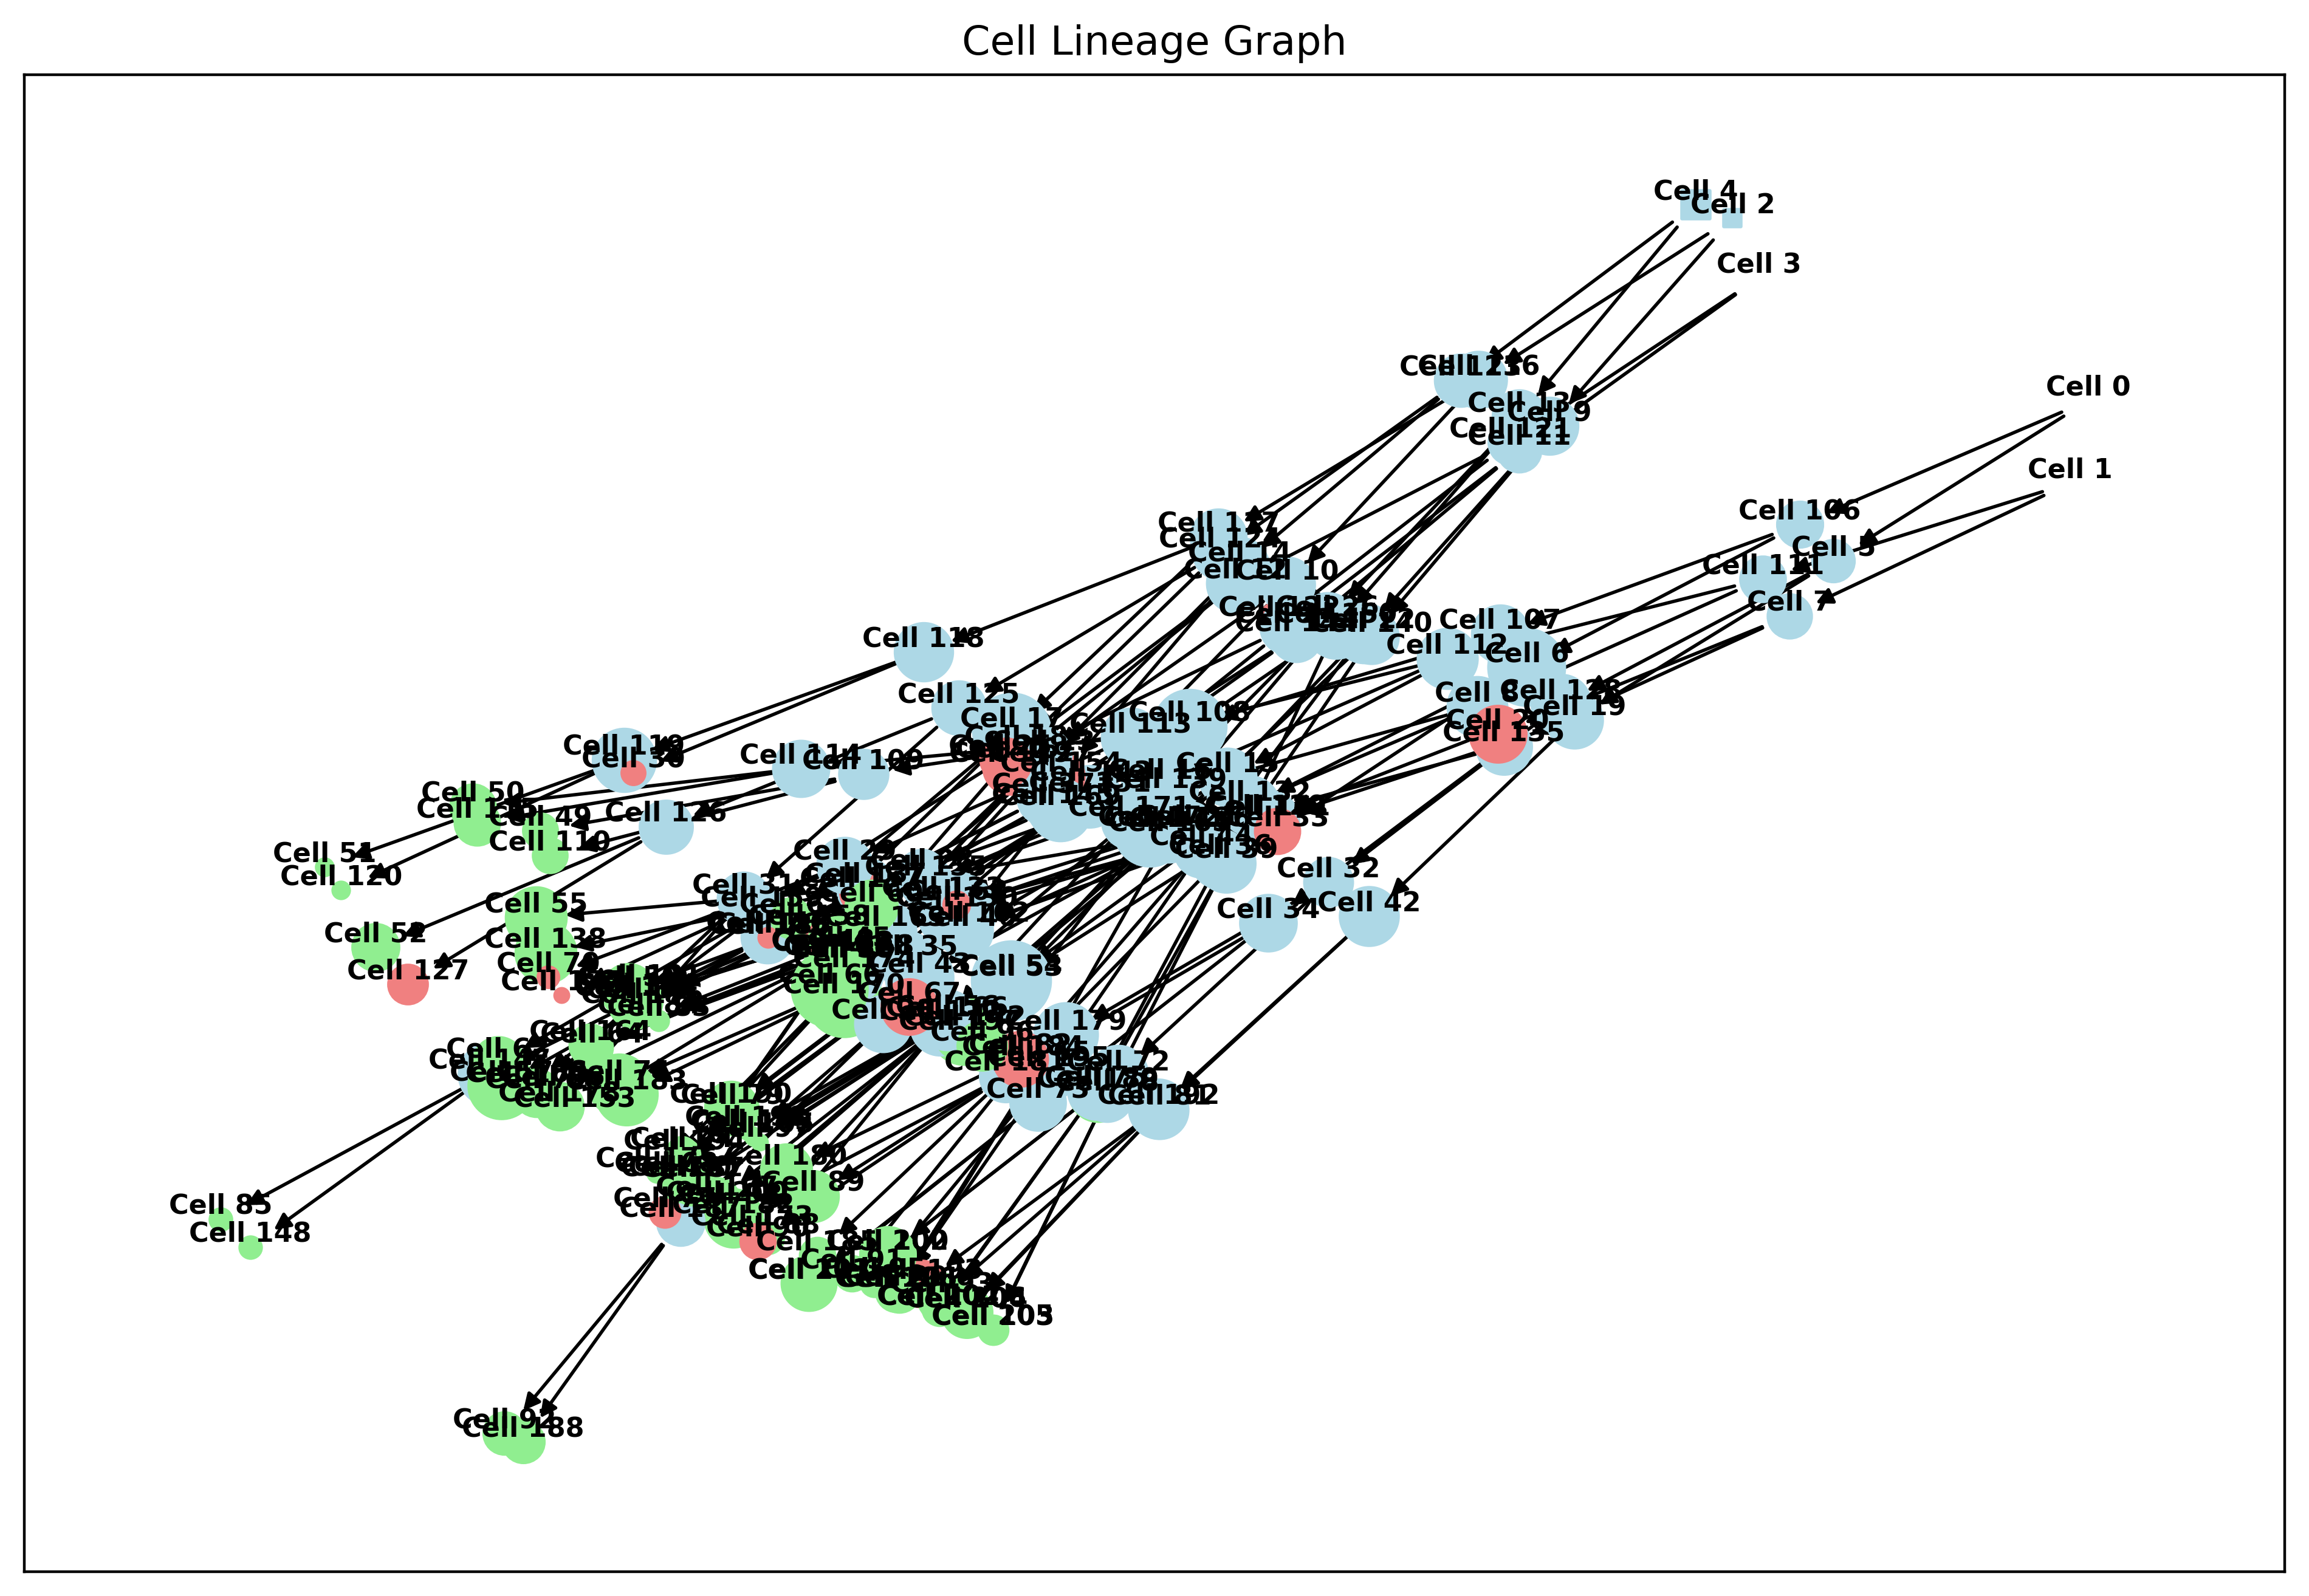

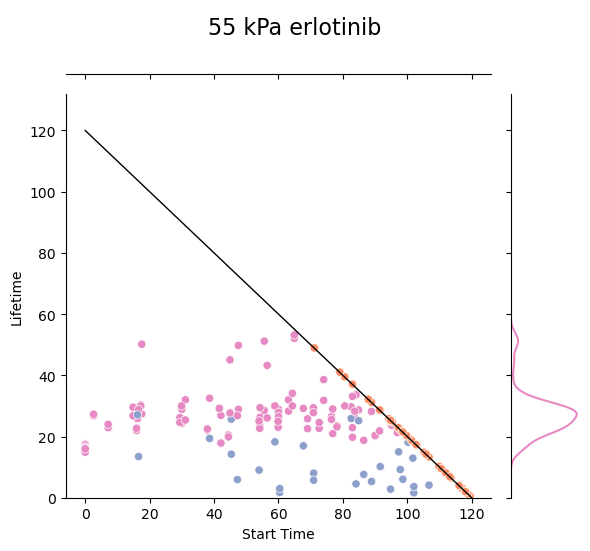

elapsed time is 0:00:01.704737 minutes


In [101]:
# add/change random seed for reproducible output
seed = 2

# Run the model
# Simulate Check_Model_Consistency
# (variable_range, check, tmp_score) = Check_Model_Consistency(model, thr=0.26, return_plot=True)

(check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=True)
current_time = datetime.datetime.now()
print(f'elapsed time is {(current_time-start_time)/60} minutes')

In [18]:
import fracprolif as fp

In [19]:
population_history = population_df
parameters_sim = {}

In [20]:
def calc_rates(population_df):
    population_history = population_df
    parameters_sim = {}
    if len(population_history) > 0:
        number_of_deaths = len(population_history) - (population_history['Event']=='Apoptosis').value_counts()[0]
        cell_time_total = sum(population_history['Lifetime'])
        parameters_sim['a'] = number_of_deaths/cell_time_total
    else:
        parameters_sim['a'] = np.nan

    population_df = population_history[population_history['Starting Cell'] == False]
    mitotic_lifespans = population_df['Lifetime'][population_df['Event'] == 'Mitosis']
    censored_lifespans = population_df['Lifetime'][population_df['Event'] == 'End of experiment']

    if len(mitotic_lifespans) > 0:
        m = fp.mle(mitotic_lifespans, censored_lifespans)
        parameters_sim['mu'] = m['x'][0]
        parameters_sim['sigma'] = m['x'][1]
        parameters_sim['lambda'] = m['x'][2]
        parameters_sim.update(fp.q_rates(m))
    else:
        parameters_sim['d'] = np.nan
        parameters_sim['q'] = np.nan
        parameters_sim['mu'] = np.nan
        parameters_sim['sigma'] = np.nan
        parameters_sim['lambda'] = np.nan
        
    return parameters_sim

In [22]:
parameters_sim

{}

In [23]:
def plot_cell_count(cell_count, run_time, title="Unknown condition"):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    fig, ax = plt.subplots()
    ax.scatter(t_sim, pop_dubs, color="black", s=1)
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Population doublings')
    ax.set_ylim(0,5)
    plt.text(0,4.5,title)
    plt.show()

    return fig, ax

In [24]:
def make_fig(cell_count, run_time, title="Unknown condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Population doublings')
    ax.set_ylim(0,5)
    plt.text(0,4.5,title)
    
    return fig, ax

In [25]:
def add_plot(cell_count, run_time, fig, ax, title="Unknown condition", color="black"):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    ax.plot(t_sim, pop_dubs, color=color, lw=0.5, alpha=0.8)

    return

### New plotting function
Use seaborn and pandas. Should also save output files as csv (or parquet or feather) to maximize cross compatibility. Simple save procedure once data are in pandas DataFrame.  

In [26]:
def make_cellcount_df(cell_count_dat):
    dtp = pd.DataFrame(cell_count_dat)
    dtp.columns = ['Time (h)','Cell count','condition']
    dtp['Population doublings'] = pd.Series([dtp['Cell count'][dtp['condition']==cond] for cond in dtp['condition'].unique()])

def plot_popgrowth(cell_count_df):
    sns.scatterplot(data=cell_count_df, x='Time (h)', y='Population doublings', hue='condition')

In [ ]:
# cells['molecules'][3]

In [27]:
model.parameters['CycDi_0'].value

0.0

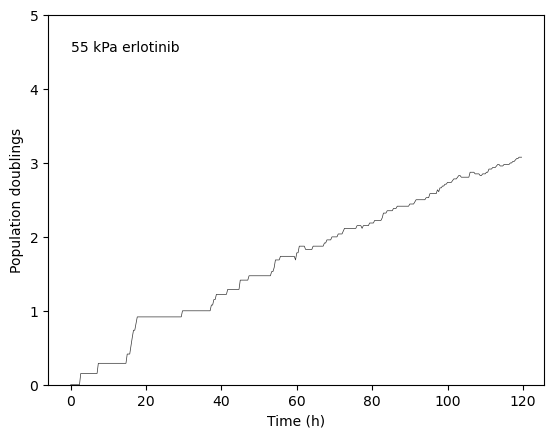

In [102]:
fig, ax = make_fig(cell_count, run_time, title=condition)
add_plot(cell_count, run_time, fig, ax, title=condition)

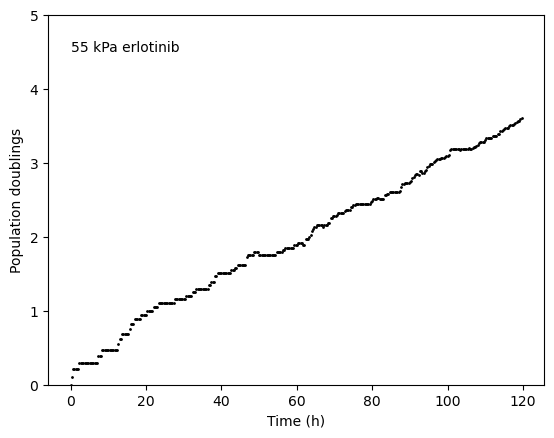

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Time (h)', ylabel='Population doublings'>)

In [41]:
plot_cell_count(cell_count, run_time, title=condition)

In [ ]:
plot_cell_count(cell_count, run_time, title=condition)

In [29]:
from call_cell_events import call_events #
from retrieve_cellState_dw_2 import retrieve_cellState #

   Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          False       False  False           0  17.558528
1          False       False  False   17.558528  27.391304
2          False       False  False   44.949833  46.956522
3          False       False  False   91.906355  18.260870
4          False        True  False  110.167224   9.732441
5          False       False  False           0  17.257525
6          False       False  False   17.257525  30.301003
7          False       False  False   47.558528  28.896321
8          False       False  False   76.454849  26.488294
9          False        True  False  102.943144  16.956522
10          True       False  False           0   2.608696
11         False       False  False    2.608696  26.789298
12         False       False  False   29.397993  26.187291
13         False       False  False   55.585284  28.494983
14         False       False  False   84.080268  33.612040
15         False        True  False  117.692308   2.2073

(0.0, 125.0)

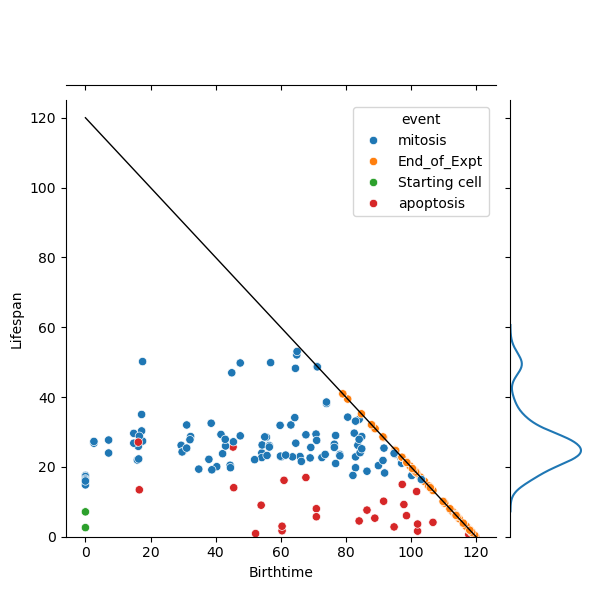

In [103]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [ ]:
all_prot

In [ ]:
all_prot['BCL2'][0]

In [ ]:
death_mod={'BAX_0': 186 ,'BAXmBCL2_0': 13, 'BH3_0': 0, 'BH3BCL2_0': 7, 'BAXm_0': 0, 'BCL2_0': 149}

In [31]:
def calc_death(cells, all_events_simulated):
    EXPT_TIME = 120
    total_time = 0
    for n in range(len(cells['time'])):
        if cells['time'][n][-1] > EXPT_TIME:
            total_time = total_time + (EXPT_TIME - cells['time'][n][0])
        else:
            total_time = total_time + (cells['time'][n][-1] - cells['time'][n][0])
    try:
        num_deaths = len(all_events_simulated[all_events_simulated['event']=='apoptosis'])
    except:
        num_deaths = 0
    a_rate = num_deaths/total_time
    
    return [a_rate, num_deaths, total_time]

In [68]:
test = calc_death(cells, all_events_simulated)
test

[0.0, 0, 1020.4854701121399]

In [ ]:
test = calc_death(cells, all_events_simulated)
test

In [33]:
len(all_events_simulated[all_events_simulated['event']=='apoptosis'])

15

In [ ]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [78]:
def run_treatment(inhib_name, inhib_conc):
    model.parameters[inhib_name].value = inhib_conc
    
    (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False)
    IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
    all_events_simulated = call_events(run_time, IMT_eoe_counts)
        
    
    return cells, cell_count, population_df
    

In [80]:
def fit_DIP(cell_count, run_time):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 20
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    dip_rate,b = np.polyfit(t_sim, pop_dubs, 1)
    
    return dip_rate

In [81]:
test = fit_DIP(cell_count, run_time)
test

0.03609535870271588

In [ ]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [104]:
condition = "55 kPa erlotinib"
concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
DIPs_di = dict([(conc, []) for conc in concs])
population_dfs = dict([(conc, []) for conc in concs])
cell_counts_di = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))


In [105]:
#fig, ax = make_fig(cell_count, run_time, title=condition)
n=0
for conc in concs:
    for i in range(3):
        cells, cell_count, population_df = run_treatment('CycDi_0', conc)
        cell_counts_di[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_di[conc].append(dip_rate)
        population_dfs[conc].append(population_df)
        add_plot(cell_count, run_time, fig, ax, title=condition, color=colors[n])
        
    n+=1
        

55 kPa erlotinib


2024-02-27 12:05:34.384 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0         False       False  False           0  29.096990
1         False       False  False    29.09699  20.769231
2         False       False  False   49.866221  54.882943
3         False        True  False  104.749164  15.150502
4          True       False  False           0   4.113712
5         False       False  False    4.113712  28.896321
6         False       False  False   33.010033  18.060201
7         False       False  False   51.070234  28.595318
8         False        True  False   79.665552  40.234114
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 6.822742474916}
55 kPa erlotinib


2024-02-27 12:07:17.597 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


   Starting cell End_of_Expt  Death   Birthtime   Lifespan
0           True       False  False           0  13.645485
1          False       False  False   13.645485  25.685619
2          False       False  False   39.331104  31.806020
3          False       False  False   71.137124  21.772575
4          False       False  False   92.909699  23.979933
5          False        True  False  116.889632   3.010033
6           True       False  False           0   5.317726
7          False       False  False    5.317726  23.478261
8          False       False  False   28.795987  21.973244
9          False       False  False   50.769231  53.177258
10         False        True  False  103.946488  15.953177
11         False       False  False           0  16.454849
12         False       False  False   16.454849  54.682274
13         False       False  False   71.137124  28.294314
14         False       False   True   99.431438   1.204013
15          True       False  False           0   6.8227

...

Empty DataFrame
Columns: [Starting cell, End_of_Expt, Death, Birthtime, Lifespan]
Index: []
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 1.505016722408}
  Starting cell End_of_Expt  Death Birthtime   Lifespan
0          True       False  False         0   1.505017
1         False       False  False  1.505017  57.591973
2         False       False   True  59.09699   0.000000
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 10.73578595318}
   Starting cell End_of_Expt  Death   Birthtime    Lifespan
0           True       False  False           0    1.505017
1          False       False  False    1.505017   57.591973
2          False       False   True    59.09699    0.000000
3           True       False  False           0   10.735786
4          False       False  False   10.735786   40.234114
5          False       False   True     50.9699   30.501672
6           True       False  False           0   13

2024-02-27 12:42:02.368 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


  Starting cell End_of_Expt  Death  Birthtime   Lifespan
0          True       False  False          0   3.311037
1         False       False  False   3.311037  45.551839
2         False        True  False  48.862876  71.036789
3         False       False  False          0  28.996656
4         False       False  False  28.996656  41.337793
5         False        True  False  70.334448  49.565217
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 13.74581939799}
  Starting cell End_of_Expt  Death  Birthtime    Lifespan
0          True       False  False          0    3.311037
1         False       False  False   3.311037   45.551839
2         False        True  False  48.862876   71.036789
3         False       False  False          0   28.996656
4         False       False  False  28.996656   41.337793
5         False        True  False  70.334448   49.565217
6          True       False  False          0   13.745819
7         False       False   T

2024-02-27 12:42:30.374 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


  Starting cell End_of_Expt  Death   Birthtime    Lifespan
0          True       False  False           0    0.602007
1         False       False  False    0.602007  115.585284
2         False        True  False  116.187291    3.712375
3          True       False  False           0    3.411371
4         False       False  False    3.411371   82.374582
5         False        True  False   85.785953   34.113712
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 1.304347826087}


In [ ]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
DIPs_ei = dict([(conc, []) for conc in concs])
cell_counts_ei = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))

fig, ax = make_fig(cell_count, run_time, title=condition)
n=0
for conc in concs:
    for i in range(3):
        cells, cell_count = run_treatment('CycEi_0', conc)
        cell_counts_ei[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_ei[conc].append(dip_rate)
        add_plot(cell_count, run_time, fig, ax, title=condition, color=colors[n])
        
    n+=1
        

In [ ]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
DIPs_ai = dict([(conc, []) for conc in concs])
cell_counts_ai = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))

fig, ax = make_fig(cell_count, run_time, title=condition)
n=0
for conc in concs:
    for i in range(3):
        cells, cell_count = run_treatment('CycAi_0', conc)
        cell_counts_ai[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_ai[conc].append(dip_rate)
        add_plot(cell_count, run_time, fig, ax, title=condition, color=colors[n])
        
    n+=1
        

In [ ]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
DIPs_bi = dict([(conc, []) for conc in concs])
cell_counts_bi = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))

fig, ax = make_fig(cell_count, run_time, title=condition)
n=0
for conc in concs:
    for i in range(3):
        cells, cell_count = run_treatment('CycBi_0', conc)
        cell_counts_bi[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_bi[conc].append(dip_rate)
        add_plot(cell_count, run_time, fig, ax, title=condition, color=colors[n])
        
    n+=1
        

In [ ]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

In [84]:
def plot_dip(concs, DIPs, title="Unknown Condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('DIP')
    plt.xscale("log")
    ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        tmp_c = [conc]*len(DIPs[conc])
        ax.scatter(tmp_c,DIPs[conc], color='black')
    
    return fig, ax

In [122]:
def plot_arate(concs, population_dfs, title="Unknown Condition"):
    fig1 = plt.figure()
    ax = fig1.add_subplot(1,1,1)
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('Apoptosis rate')
    ax.set_xscale("log")
    ax.set_xlim(1.0e-10, 1.0e-4)
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        a_rates = []
        for num in range(3):
            tmp_rates = calc_rates(population_dfs[conc][num])
            a_rates.append(tmp_rates['a'])

        tmp_c = [conc*10e-7]*3
        ax.scatter(tmp_c,a_rates, color='black')
    
    return fig, ax

In [123]:
def plot_drate(concs, population_dfs, title="Unknown Condition"):
    fig1 = plt.figure()
    ax = fig1.add_subplot(1,1,1)
    
    ax.set_xlabel('CycDi (M)')
    ax.set_ylabel('Division rate')
    ax.set_xscale("log")
    ax.set_xlim(1.0e-10, 1.0e-4)
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        d_rates = []
        for num in range(3):
            tmp_rates = calc_rates(population_dfs[conc][num])
            d_rates.append(tmp_rates['d'])

        tmp_c = [conc*10e-7]*3
        ax.scatter(tmp_c,d_rates, color='black')
    
    return fig, ax

In [87]:
def plot_qrate(concs, population_dfs, title="Unknown Condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('Quiescence rate')
    plt.xscale("log")
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        q_rates = []
        for num in range(3):
            tmp_rates = calc_rates(population_dfs[conc][num])
            q_rates.append(tmp_rates['q'])

        tmp_c = [conc*10e-7]*3
        ax.scatter(tmp_c,q_rates, color='black')
    
    return fig, ax

In [88]:
def plot_daratio(concs, population_dfs, title="Unknown Condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('Division/Apoptosis rate')
    plt.xscale("log")
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        d_rates = []
        a_rates = []
        for num in range(3):
            tmp_rates = calc_rates(population_dfs[conc][num])
            d_rates.append(tmp_rates['d'])
            a_rates.append(tmp_rates['a'])
            
            d_a = np.mean(d_rates)/np.mean(a_rates)

        tmp_c = [conc*10e-7]*1
        ax.scatter(tmp_c,d_a, color='black')
    
    return fig, ax

In [107]:
calc_rates(population_df)

{'a': 0.0024945752881568094,
 'mu': 82.88104565405047,
 'sigma': 32.50041251225668,
 'lambda': 0.0914343194000906,
 'd': 0.007695964119734131,
 'q': 7.695964119734131e-44}

In [117]:
no_divs = {0: [0.0061512720830667784, 0.005354565348977975, 0.004729343606518611],
 0.001: [0.005728232715680414, 0.004926530437390224, 0.004906570715950444],
 0.01: [0.006281249214843848, 0.0052431511338314335, 0.004284091120755491],
 0.025: [0.005657708628005658, 0.005955642375586631, 0.005131055714713302],
 0.05: [0.006316454363617221, 0.006013807702484905, 0.005451373746184037],
 0.075: [0.0052501476604029495, 0.005067088248408934, 0.0055289347585698485],
 0.1: [0.007584951456310679, 0.006427595811350063, 0.004793264421473824],
 0.25: [0.005138416083242341, 0.004911276718413016, 0.006476851731910153],
 0.5: [0.004729493532931669, 0.004649000464900046, 0.007585641897017326],
 1: [0.005850661856122473, 0.004396570674873598, 0.0050784856879039705],
 2: [0.005396290050590219, 0.004602903665062042, 0.007363553356307619],
 5: [0.005354440693749273, 0.006975446428571428, 0.007466252538525863],
 10: [0.005457770500750442, 0.0032538313864575535, 0.004225999081304547]}

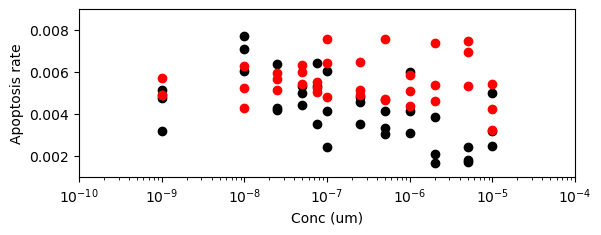

In [119]:
fig, ax = plot_arate(concs, population_dfs, title="Unknown Condition")
ax.set_xlim(1.0e-10, 1.0e-4)
ax.set_ylim(0.001,0.009)

#plt.text(0,4.5,title)
for conc in concs:
#     a_rates = []
#     for num in range(3):
# #         tmp_rates = calc_rates(population_dfs[conc][num])
#         a_rates.append(tmp_rates['a'])

    tmp_c = [conc*10e-7]*3
    ax.scatter(tmp_c,no_divs[conc], color='red')

Text(0, 0.5, 'Division or Apoptosis rate')

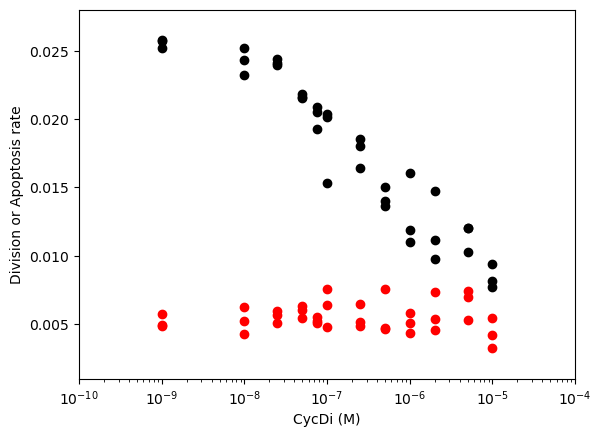

In [128]:
fig, ax = plot_drate(concs, population_dfs, title="Unknown Condition")

ax.set_xlim(1.0e-10, 1.0e-4)
ax.set_ylim(0.001,0.028)
#plt.text(0,4.5,title)
for conc in concs:
#     a_rates = []
#     for num in range(3):
# #         tmp_rates = calc_rates(population_dfs[conc][num])
#         a_rates.append(tmp_rates['a'])

    tmp_c = [conc*10e-7]*3
    ax.scatter(tmp_c,no_divs[conc], color='red')
    
ax.set_ylabel('Division or Apoptosis rate')

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (3,) + inhomogeneous part.

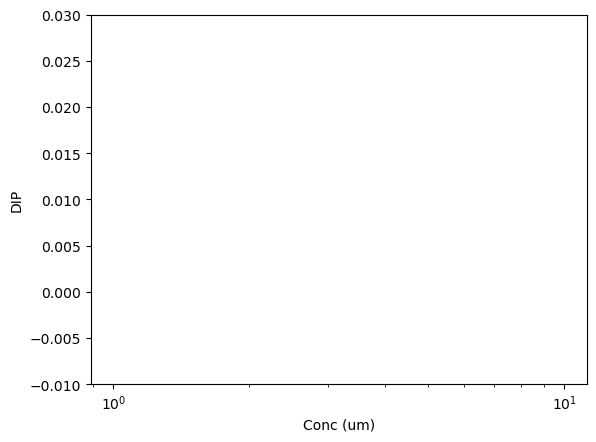

In [120]:
plot_dip(concs, population_dfs, title="Unknown Condition")

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='CycDi (M)', ylabel='Division rate'>)

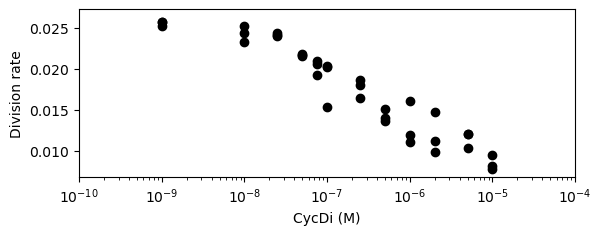

In [108]:
plot_drate(concs, population_dfs, title="Unknown Condition")

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Conc (um)', ylabel='Quiescence rate'>)

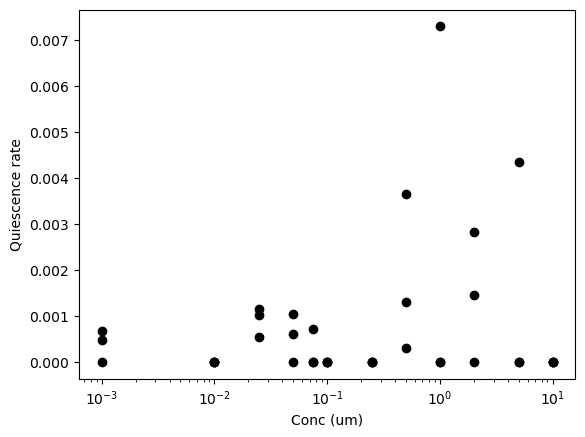

In [91]:
plot_qrate(concs, population_dfs, title="Unknown Condition")

In [ ]:
plot_daratio(concs, population_dfs, title="Unknown Condition")

In [109]:
a_rate_di[concs[0]]

NameError: name 'a_rate_di' is not defined

(<Figure size 640x480 with 1 Axes>, <Axes: xlabel='Conc (um)', ylabel='DIP'>)

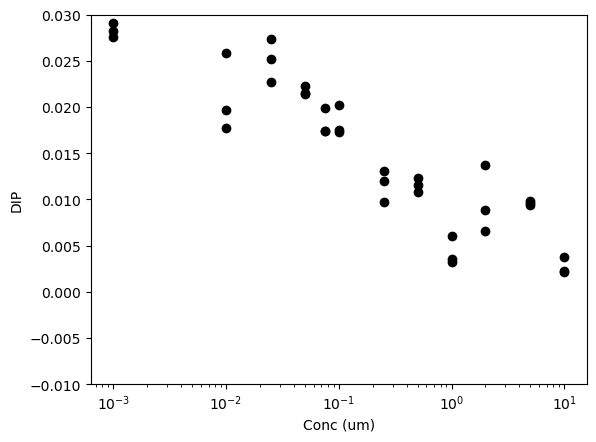

In [121]:
plot_dip(concs, DIPs_di, title="Unknown Condition")

In [ ]:
plot_dip(concs, DIPs_di, title="Unknown Condition")

In [ ]:
plot_dip(concs, DIPs_ai, title="Unknown Condition")

In [ ]:
plot_dip(concs, DIPs_bi, title="Unknown Condition")

In [ ]:
cell_counts_dil = {}
for cond in cell_counts_di:
    tmp = [run.tolist() for run in cell_counts_di[cond]]
    cell_counts_dil.update({cond: tmp})

In [ ]:
a_rates_dil = {}
for cond in a_rate_di:
    tmp = [run for run in a_rate_di[cond]]
    a_rates_dil.update({cond: tmp})

In [ ]:
    
cell_counts_eil = {}
for cond in cell_counts_ei:
    tmp = [run.tolist() for run in cell_counts_ei[cond]]
    cell_counts_eil.update({cond: tmp})
    
cell_counts_ail = {}
for cond in cell_counts_ai:
    tmp = [run.tolist() for run in cell_counts_ai[cond]]
    cell_counts_ail.update({cond: tmp})
    
cell_counts_bil = {}
for cond in cell_counts_bi:
    tmp = [run.tolist() for run in cell_counts_bi[cond]]
    cell_counts_bil.update({cond: tmp})

In [ ]:
import json

# e.g. file = './data.json' 
with open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_06kpa_erl.json', 'w') as f: 
    json.dump(cell_counts_dil, f)

In [ ]:
# e.g. file = './data.json' 
with open('C:\\Users\\olesk\\ECM_mod_output\\arates_di_4kpa_erl.json', 'w') as f: 
    json.dump(a_rates_dil, f)

In [ ]:
plt.plot(cell_counts_di[0][0][:,0], cell_counts_di[0][0][:,1])
cell_counts_di[0][0]

In [ ]:
    
with open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_ei_4kpa_erl.json', 'w') as f: 
    json.dump(cell_counts_eil, f)
    
with open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_ai_4kpa_erl.json', 'w') as f: 
    json.dump(cell_counts_ail, f)
    
with open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_bi_4kpa_erl.json', 'w') as f: 
    json.dump(cell_counts_bil, f)

In [ ]:
fig, ax = make_fig(cell_count, run_time, title=condition)
add_plot(cell_count, run_time, fig, ax, title=condition)
add_plot(cell_count_1, run_time, fig, ax, title=condition, color='red')

In [ ]:
def runIMTs(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, IMTs_count):
    all_IMTs = []
    n = 0
    while len(all_IMTs)<IMTs_count:
        (population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=0.26, return_plot=False)

        IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
        all_events_simulated = call_events(run_time, IMT_eoe_counts)
        
        mits = all_events_simulated.loc[all_events_simulated['event']=='mitosis'].reset_index()
        mits_list = mits['Lifespan'].tolist()
        mits_list_r = [round(x,1) for x in mits_list]
        
        if n==0:
            all_IMTs = mits_list_r
        else:
            all_IMTs.extend(mits_list_r)
        
        filename_cell_count = Path(SAVE_DIR, f'cell_counts_{condition}_{n}_param_orig.csv')
        np.savetxt(filename_cell_count, cell_count, delimiter=',')
        
        n+=1
        
    filename_IMT = Path(SAVE_DIR, f'IMTs_{condition}_param_orig.csv')
    np.savetxt(filename_IMT, all_IMTs, delimiter=',')

In [ ]:
condition = "0.6 kPa erlotinib"

In [ ]:
runIMTs(20, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 200)

In [ ]:
condition = "4 kPa DMSO"

In [ ]:
all_IMTs = []
n = 2

(population_df, cells, cell_count) = Cell_Population_Simulation(5, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=0.26, return_plot=False)

IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts)

mits = all_events_simulated.loc[all_events_simulated['event']=='mitosis'].reset_index()
mits_list = mits['Lifespan'].tolist()
mits_list_r = [round(x,1) for x in mits_list]

if n==0:
    all_IMTs = mits_list_r
else:
    all_IMTs.extend(mits_list_r)

filename_cell_count = Path(SAVE_DIR, f'cell_counts_{condition}_{n}_param_orig.csv')
np.savetxt(filename_cell_count, cell_count, delimiter=',')

n+=1

In [ ]:
all_conditions = ['0.6 kPa DMSO', '4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

In [ ]:
for condition in all_conditions:
    runIMTs(5, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 200)

In [ ]:
death_before_division = len(max_tmp_cdc)==0 or np.min(death) < max_tmp_cdc[min([cells['division'][0], len(max_tmp_cdc)-1])]
death_before_division

In [ ]:
div_ind=[]
len(div_ind)

In [ ]:
start = all_events_simulated.loc[all_events_simulated['event']=='Starting cell']
start

In [ ]:
mits = all_events_simulated.loc[all_events_simulated['event']=='mitosis'].reset_index()

In [ ]:
mits_list = mits['Lifespan'].tolist()
mits_list_r = [round(x,1) for x in mits_list]
mits_list_r

In [ ]:
cells['living_cell'][0]

In [ ]:
cells['division'][0]

In [ ]:
plt.plot(cells['time'][0],cells['molecules'][0]['obsBAXm'])
plt.plot(cells['time'][0],cells['molecules'][0]['obsCdc20'])

In [ ]:
start_time = datetime.datetime.now()

conditions = ['4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']


for condition in conditions:
    for num in range(3):
        init = 5
        
        (cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, seed=seed)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

In [ ]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 10
        
        (cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, seed=seed)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")

In [ ]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

fig, ax = plt.subplots()
for condition in conditions:
    for num in range(3):
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')

        print(f"Loading {filename}...")
        cell_count = np.loadtxt(filename, delimiter=',')
        
        t_sim = np.arange(0, 120, 1 / 3)
        cell_count_t = np.zeros(len(t_sim))
        time_tmp_m = 0
        for time_tmp_p, cell_count_time_tmp in cell_count:
            cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
            time_tmp_m = time_tmp_p
        DIP_sim = np.log2(cell_count_t / cell_count_t[0])
        if "erlotinib" in str(filename):
            ax.scatter(t_sim, DIP_sim, color="red", s=1)
        else:
            ax.scatter(t_sim, DIP_sim, color="blue", s=1)
ax.set_xlabel('Time (h)')
ax.set_ylabel('Population doublings')
ax.set_ylim(0,5)
plt.text(0,4.75,conditions[1])
plt.text(0,4.45,conditions[0])
plt.show()

In [ ]:
conditions = ['4 kPa erlotinib', '4 kPa DMSO']

fig, ax = plt.subplots()
for condition in conditions:
    for num in range(3):
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')

        print(f"Loading {filename}...")
        cell_count = np.loadtxt(filename, delimiter=',')
        
        t_sim = np.arange(0, 120, 1 / 3)
        cell_count_t = np.zeros(len(t_sim))
        time_tmp_m = 0
        for time_tmp_p, cell_count_time_tmp in cell_count:
            cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
            time_tmp_m = time_tmp_p
        DIP_sim = np.log2(cell_count_t / cell_count_t[0])
        if "erlotinib" in str(filename):
            ax.scatter(t_sim, DIP_sim, color="red", s=1)
        else:
            ax.scatter(t_sim, DIP_sim, color="blue", s=1)
ax.set_xlabel('Time (h)')
ax.set_ylabel('Population doublings')
ax.set_ylim(0,5)
plt.text(0,4.75,conditions[1])
plt.text(0,4.45,conditions[0])
plt.show()

In [ ]:
conditions = ['55 kPa erlotinib', '55 kPa DMSO']

fig, ax = plt.subplots()
for condition in conditions:
    for num in range(3):
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')

        print(f"Loading {filename}...")
        cell_count = np.loadtxt(filename, delimiter=',')
        
        t_sim = np.arange(0, 120, 1 / 3)
        cell_count_t = np.zeros(len(t_sim))
        time_tmp_m = 0
        for time_tmp_p, cell_count_time_tmp in cell_count:
            cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
            time_tmp_m = time_tmp_p
        DIP_sim = np.log2(cell_count_t / cell_count_t[0])
        if "erlotinib" in str(filename):
            ax.scatter(t_sim, DIP_sim, color="red", s=1)
        else:
            ax.scatter(t_sim, DIP_sim, color="blue", s=1)
ax.set_xlabel('Time (h)')
ax.set_ylabel('Population doublings')
ax.set_ylim(0,5)
plt.text(0,4.75,conditions[1])
plt.text(0,4.45,conditions[0])
plt.show()